In [33]:
# Implement a Decision Tree classifier using the ID3 algorithm to segment customers based
# on their purchasing behavior using the Online Retail dataset. Analyze the tree structure
# and discuss the feature importance.
# Tasks:
# ● Load and preprocess the Online Retail dataset.
# ● Implement Decision Tree using the ID3 algorithm.
# ● Visualize the decision tree and analyze feature importance.
# ● Discuss how the tree structure helps in understanding customer behavior.

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier , plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,classification_report

In [35]:
data = pd.read_csv(".\OnlineRetail.csv" , encoding='latin1')
data

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France


In [36]:
data = data.dropna()
data['TotalAmount'] = data['Quantity'] * data ['UnitPrice']
customer_data = data.groupby(
    'CustomerID'
).agg({
    'TotalAmount': 'sum',
    'Quantity': 'sum',
    'InvoiceNo': 'nunique'
})

customer_data.columns = [
    'TotalSpending',
    'TotalQuantity',
    'NumTransactions'
]
median_spending = customer_data[
    'TotalSpending'
].median()

customer_data['Segment'] = (
    customer_data['TotalSpending']
    > median_spending
).astype(int)

In [37]:
customer_data

,TotalSpending,TotalQuantity,NumTransactions,Segment
CustomerID,,,,
12346.0,0.00,0,2,0
12347.0,4310.00,2458,7,1
12348.0,1797.24,2341,4,1
12349.0,1757.55,631,1,1
12350.0,334.40,197,1,0
...,...,...,...,...
18280.0,180.60,45,1,0
18281.0,80.82,54,1,0
18282.0,176.60,98,3,0


In [38]:
x = customer_data[
    [
        'TotalSpending',
        'TotalQuantity',
        'NumTransactions'
    ]
]

y = customer_data['Segment']

In [39]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2)

In [40]:
# Decision Tree
model = DecisionTreeClassifier(criterion = 'entropy',max_depth = 3)
model.fit(x_train,y_train)
pred = model.predict(x_test)
print("Accuracy:",accuracy_score(y_test, pred))
print(classification_report(y_test,pred))

Accuracy: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       434
           1       1.00      1.00      1.00       441

    accuracy                           1.00       875
   macro avg       1.00      1.00      1.00       875
weighted avg       1.00      1.00      1.00       875



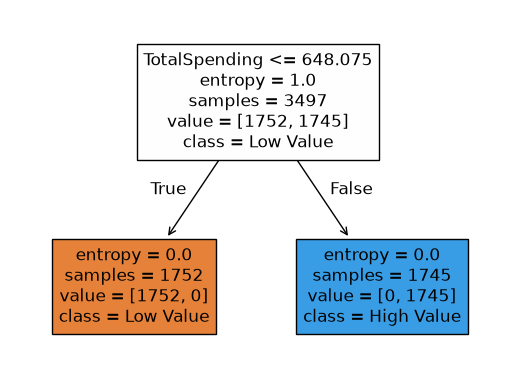

In [43]:
plot_tree(model,feature_names = x.columns,class_names=["Low Value","High Value"],filled = True)
plt.show()